In [2]:
import torch
from torch.utils.data import Dataset

In [3]:
torch.manual_seed(42)

In [6]:
x = (((torch.rand(1000)) * 4) - 2 ).view(-1,1)
y = x * 2 + 1 + torch.randn(1000,1) * 0.1

In [7]:
class LinearDataset(Dataset):
  def __init__(self,x,y):
    super().__init__()
    self.x = x
    self.y = y

  def __len__(self):
    return len(self.x)

  def __getitem__(self, index):
    return self.x[index],self.y[index]

In [9]:
from torch.utils.data import random_split,DataLoader

In [10]:
dataset = LinearDataset(x,y)
train_size = 800
val_size = 200

In [11]:
train_dataset,val_dataset = random_split(dataset,[train_size,val_size])

In [12]:
train_loader = DataLoader(dataset=train_dataset,batch_size=32,shuffle=True)
val_loader = DataLoader(dataset=val_dataset,batch_size=32,shuffle=False)

In [13]:
import torch.nn as nn

In [14]:
model = nn.Linear(1,1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(),lr=0.1)

In [17]:
epoches = 30
train_losses = []
val_losses = []

In [20]:
for epoch in range(epoches):
  train_epoch_loss = 0.0
  train_samples = 0.0

  val_epoch_loss = 0.0
  val_samples = 0.0
  model.train()

  for batchx,batchy in train_loader:
    optimizer.zero_grad()
    pred = model(batchx)
    loss = criterion(pred,batchy)

    n = batchx.size(0)
    train_epoch_loss += loss.item() * n
    train_samples += n
    loss.backward()
    optimizer.step()

  model.eval()
  with torch.no_grad():
    for batchx,batchy in val_loader:
      pred = model(batchx)
      loss = criterion(pred,batchy)
      n = batchx.size(0)
      val_epoch_loss += loss.item() * n
      val_samples += n

epoch_train_loss = train_epoch_loss / train_samples
epoch_val_loss = val_epoch_loss / val_samples

train_losses.append(epoch_train_loss)
val_losses.append(epoch_val_loss)


print(f"Epoch {epoch+1:02d} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

Epoch 30 | Train Loss: 0.0097 | Val Loss: 0.0088


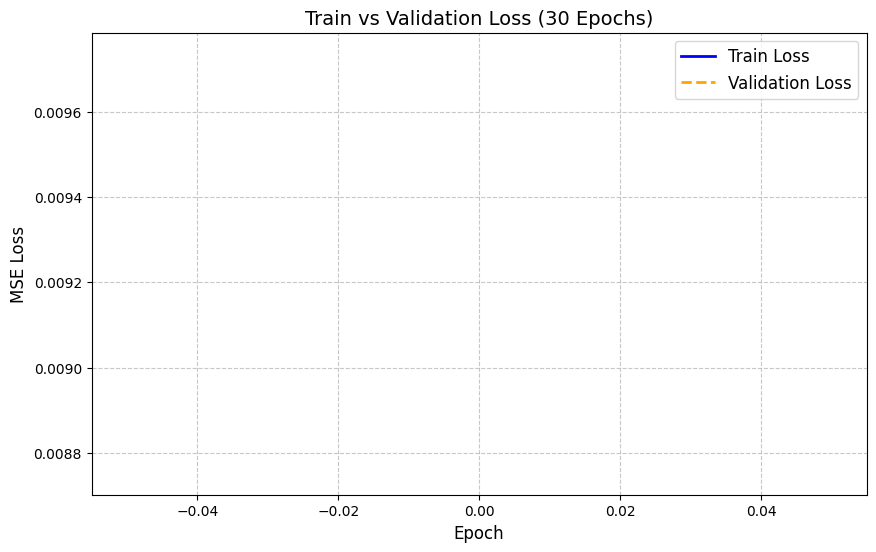

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# 直接传列表，不用给 x 参数
plt.plot(train_losses, label='Train Loss', color='blue', linewidth=2)
plt.plot(val_losses, label='Validation Loss', color='orange', linewidth=2, linestyle='--')

plt.title('Train vs Validation Loss (30 Epochs)', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('MSE Loss', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()